In [1]:
%matplotlib inline 

In [2]:
import os
import io
import re
import itertools
import pandas as pd
import json

In [3]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa', 'msoa']
sample_sizes = ['sample_perc_10']

export = True
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, sample_sizes))

In [4]:
def prepare_results_filepaths(flpaths, run_results_fldr):

    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['tours_mdl_descr'] = os.path.join(run_results_fldr, 'tours_mdl_descr.csv')
    flpaths['tours_mdl_info'] = os.path.join(run_results_fldr, 'tours_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')

    return flpaths

In [5]:
def get_optimisation_results(infilepath):
    with open(infilepath) as f:
        data = json.load(f)

        results = data['Solution'][1]['Variable']

        df_data = list()
        for chain, val in results.items():
            cid = re.search('\[(\d+)\]', chain, re.DOTALL).group(1)
            times_used = val['Value']
            df_data.append([int(cid), times_used])

        s = pd.DataFrame(df_data, columns=['Tripchainid', 'TimesUsed']).set_index('Tripchainid').squeeze()
        print('dtype of optimisation results before conversion to integer: {}'.format(s.dtype))
        s = s.astype(int)
        s = s[s>0]
        return s

In [6]:
def convert_optimisation_output_to_trips(tcs_descr, optim_output):
    # Calculate how many times the tripchain has been used by the optimiser 
    df = tcs_descr.join(optim_output, how='right')
    grpby_cols = ['Source', 'Target', 'Purpose', 'Timeperiod']
    optimisation_trips = df.groupby(grpby_cols)['TimesUsed'].sum().squeeze()
    optimisation_trips.name = 'ModelledTrips'
    return optimisation_trips


In [7]:
def get_modelled_trips(paths):
    
    tcs_descr = pd.read_csv(paths['tours_mdl_descr'], index_col=['Tripchainid'])
    optim_output = get_optimisation_results(paths['optimisation_results'])
    
    if optim_output is not None:
        optimisation_trips = convert_optimisation_output_to_trips(tcs_descr, optim_output)
        return optimisation_trips, optim_output
    else:
        return None

In [8]:
def prepare_ods_comparison(optim_ods, obs_ods):
    obs_ods.name = 'ObservedTrips'
    comp = obs_ods.to_frame().join(optim_ods)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [9]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [10]:
def prepare_ditribution_comparison(fldrpaths):
    tcs_info = pd.read_csv(fldrpaths['tours_mdl_info'], index_col=['Tripchainid'])
    optim_output = get_optimisation_results(fldrpaths['optimisation_results'])
    observed_distr = pd.read_csv(fldrpaths['observed_distribution'], index_col='Distrgroupid')
    observed_distr.drop(columns=['Size'], inplace=True)

    df = tcs_info.join(optim_output, how='right')
    optim_distr = df.groupby('Distrgroupid')['TimesUsed'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in observed_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    observed_distr.set_index(idx_cols, append=True, inplace=True)
    observed_distr = observed_distr.squeeze()
    
    distr_comp = observed_distr.to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['Observed', 'Modelled']
    distr_comp.columns.name = 'Source'
    distr_comp = distr_comp.stack()
    distr_comp.name = 'Percentage'

    return distr_comp

In [11]:
def collapse_tour_legs(tours, leg_descr_cols):
    seqs = list()
    for c in leg_descr_cols:
        seq = tours.groupby('Tripchainid')[c].apply(tuple)
        seqs.append(seq)
    
    tours_collapsed = pd.concat(seqs, axis=1)
    
    return tours_collapsed

In [12]:
def prepare_descr_comparison(flpaths, mdl_nchains):
    tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])
    tours_mdl = pd.read_csv(flpaths['tours_mdl_descr'], index_col=[0, 1])

    # Standardising frames
    cmn_idx_names = ['Tripchainid', 'Legidx']
    tours_obs.index.names = cmn_idx_names
    tours_mdl.index.names = cmn_idx_names

    # Kepp only the used tripchains
    tours_mdl_used = tours_mdl.unstack().loc[mdl_nchains.index].stack()
    
    # Split Purpose in purpose and direction
    tours_mdl_used['Purpose'], tours_mdl_used['Direction'] = tours_mdl_used['Purpose'].str.split('_', 1).str

    
    leg_descr_cols = [['Source', 'Purpose', 'Timeperiod'],
                      ['Source', 'Purpose']]
    
    comps = list()
    for ldc in leg_descr_cols:
        tours_obs_clpsd = collapse_tour_legs(tours_obs, ldc)
        tours_mdl_clpsd = collapse_tour_legs(tours_mdl_used, ldc)

        comp = pd.merge(left=tours_obs_clpsd.reset_index(), right=tours_mdl_clpsd.reset_index(),
                        on=ldc, how='outer', suffixes=('_obs', '_mdl'),
                        indicator='Exist')

        comp.drop(columns=ldc, inplace=True)
        #comp = comp.squeeze()

        comp['Exist'] = comp['Exist'].str.replace('left_only', 'obs_only')
        comp['Exist'] = comp['Exist'].str.replace('right_only', 'mdl_only')
        
        comp['DescrCompDims'] = '-'.join(ldc)
        comp.set_index('DescrCompDims', append=True, inplace=True)
        comps.append(comp)
    
    comps = pd.concat(comps)
    
    return comps

In [13]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [14]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [15]:
def main(model_info):

    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    generation_inputs_fldr = r'../inputs/{}/{}/{}'.format(data_source, aggr_level, sample_size)

    params = get_input_params_from_folder(results_folder)

    concat_mdl_ods = list()
    concat_obs_ods = list()

    concat_tours_mdl_nchains = list()
    
    concat_comp_distrs = list()
    concat_comp_descrs = list()

    flpaths = dict()
    flpaths['tours_obs_descr'] = os.path.join(generation_inputs_fldr, 'obs_tours_descr.csv')
    flpaths['tours_obs_info'] = os.path.join(generation_inputs_fldr, 'obs_tours_info.csv')
    tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])
    
    for legs, trips_thresh, distr_constr_enabled in params:
        print(aggr_level)
        print(legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(flpaths, run_results_fldr)

        mdl_od, mdl_nchains = get_modelled_trips(flpaths)

        if mdl_od is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_ditribution_comparison(flpaths)
        comp_descr = prepare_descr_comparison(flpaths, mdl_nchains)

        idx_cols_od = ['Source', 'Target', 'Purpose', 'Timeperiod']
        obs_od = pd.read_csv(flpaths['od'], index_col=idx_cols_od)
        obs_od.drop(columns=['LegId'], inplace=True)

        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        obs_od = include_run_info(obs_od, d_run_info)
        mdl_od = include_run_info(mdl_od, d_run_info)
        mdl_nchains = include_run_info(mdl_nchains, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)

        concat_mdl_ods.append(mdl_od)
        concat_obs_ods.append(obs_od)
        concat_tours_mdl_nchains.append(mdl_nchains)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)

    mdl_nchains = pd.concat(concat_tours_mdl_nchains)

    ods_mdl = pd.concat(concat_mdl_ods)
    ods_obs = pd.concat(concat_obs_ods)

    comp_ods = prepare_ods_comparison(ods_mdl, ods_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    
    return comp_ods, comp_distrs, comp_descrs

In [16]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()

for ri in run_info:
    comp_ods, comp_distrs, comp_descrs = main(list(ri))
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)

comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)

if export:
    if not os.path.exists(out_folder):
        os.makedirs(out_folder)
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)

lsoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 True
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
msoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
msoa
5 1 True
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 True
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
msoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optim

In [17]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Modelled)

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [18]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [19]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
#filters['DistrDims'] = 'Distancegroup-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_10'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1

In [20]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

False
True


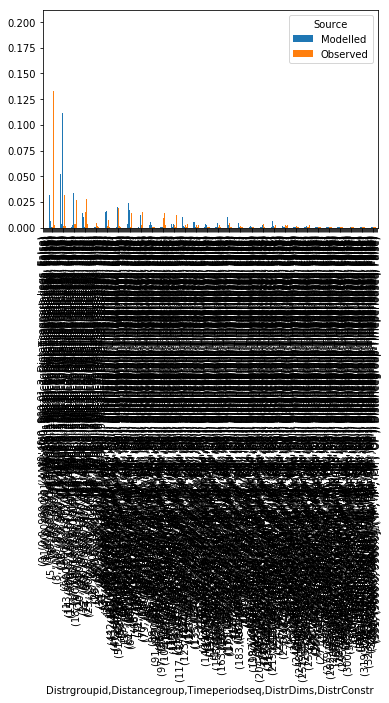

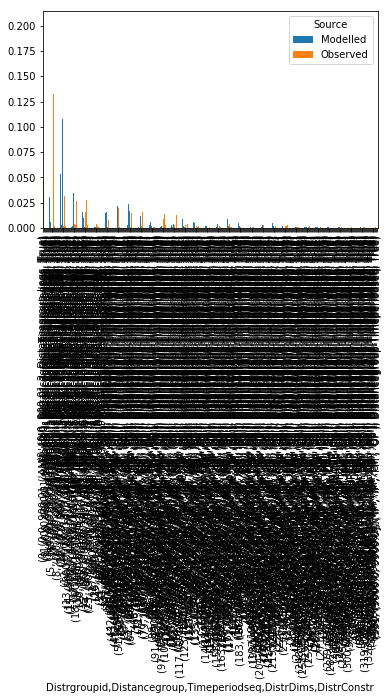

In [21]:
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
for k, g in dfg:
    print(k)
    plt = g.unstack('Source')
    plt.plot(kind='bar')

In [22]:
grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrDims', 'DescrCompDims', 'DistrConstr', 'Exist']
grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

DistrConstr                                                     False  True 
DistrDims                   DescrCompDims             Exist                 
Distancegroup-Legs          Source-Purpose            both       2902   2868
                                                      mdl_only    123    163
                                                      obs_only    133    167
                            Source-Purpose-Timeperiod both       2730   2706
                                                      mdl_only    233    263
                                                      obs_only    245    269
Distancegroup-Timeperiodseq Source-Purpose            both       2954   2913
                                                      mdl_only     86    114
                                                      obs_only     85    124
                            Source-Purpose-Timeperiod both       2778   2741
                                                      mdl_only    197    223
                                                      obs_only    197    234